# Environments and kernels

### 1. Using existing environments

You can access a list of existing environments by opening a notebook (or creating a new one) and clicking the kernel name next to the debugging icon.

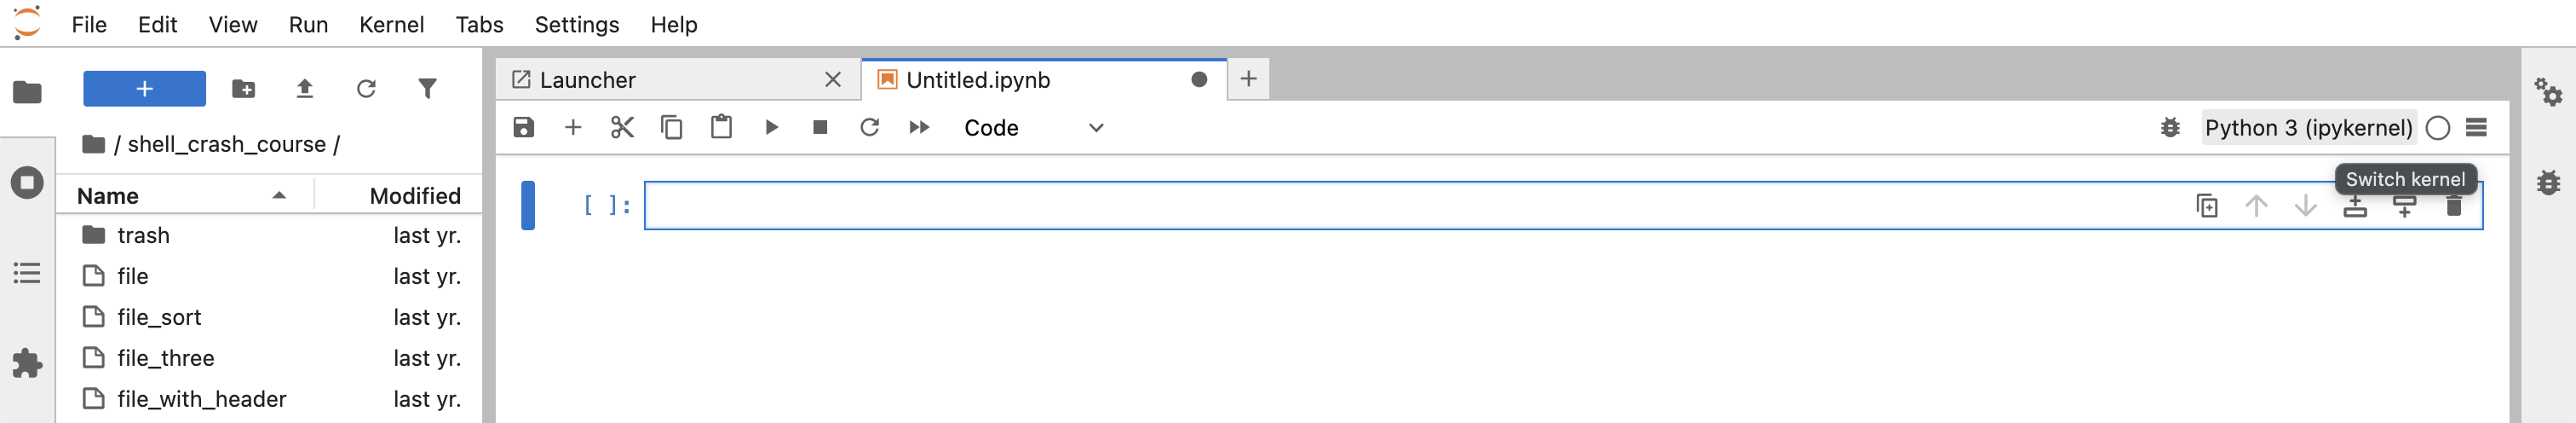

### 2. Creating your own environments

Some notebooks use mamba to create new environments specific to their analysis. Install miniforge so that you can use mamba.

In [ ]:
wget https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh
bash Miniforge3-Linux-x86_64.sh -b -p "$HOME/miniforge3"

You need to remind the server you want to use mamba each time by sourcing

In [ ]:
source "$HOME/miniforge3/etc/profile.d/conda.sh"

create an environment once using 'mamba create' with -n to specify the name and -c to specify packages you want in your environment.

In [ ]:
mamba create -n bash-tutorial -c conda-forge -c bioconda meme bedtools jupyter -y

Activate the environment (load all its packages)

In [ ]:
conda activate bash-tutorial

Oh no! We forgot to add the package samtools! No worries, install it after activating the environment:

In [ ]:
mamba install -c conda-forge -c bioconda samtools

In [ ]:
bedtools --version
samtools --version
meme -version

### Now we can use this environment directly in jupyter by wrapping it in a kernel

Find out where jupyter stores its data and make the directory for your kernel

In [ ]:
KERNEL_DIR=$(jupyter --data-dir)/kernels/bash-tutorial
mkdir -p ${KERNEL_DIR}

Manually put a kernel json in there, jupyter will read this to link the jupyter notebook editor to the env

In [ ]:
cat > ${KERNEL_DIR}/kernel.json << EOF
{
  "argv": ["${CONDA_PREFIX}/bin/python", "-m", "bash_kernel", "-f", "{connection_file}"],
  "display_name": "Tutorial kernels",
  "language": "bash",
  "env": {"PATH": "${CONDA_PREFIX}/bin:/usr/local/bin:/usr/bin:/bin", "PS1": "$"}
}
EOF

Check if it's really there

In [ ]:
jupyter kernelspec list

Now you can access that env as a kernel in jupyter notebook editor